# 02 — Aprendizaje no supervisado con UNSW-NB15
**Equipo 1 — perfiles de tráfico, agrupamiento y anomalías**

**Integrantes:** Integrante 1 · Integrante 2 · Integrante 3 · Integrante 4  
**Asignatura:** Análisis de Datos · **Periodo:** 2026-2

Notebook independiente y reproducible. La etiqueta `attack` no entra al escalamiento, PCA, K-Means,
GMM, cálculo de perfiles ni puntuación de anomalías. Se conserva aparte solo para muestreo
estratificado representativo y para interpretación post-hoc, tal como permite el enunciado.

In [1]:
from pathlib import Path
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import softmax
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, average_precision_score,
    balanced_accuracy_score, calinski_harabasz_score, classification_report,
    completeness_score, confusion_matrix, davies_bouldin_score, f1_score,
    homogeneity_score, normalized_mutual_info_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score,
    v_measure_score
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler, label_binarize
from sklearn.svm import OneClassSVM, SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 110, "savefig.dpi": 180})

MODE = "no_supervisado"
ROOT = Path.cwd()
VIS_DIR = ROOT / "visualizaciones" / MODE
RES_DIR = ROOT / "resultados" / MODE
CACHE_DIR = ROOT / ".cache_ml"
for folder in (VIS_DIR, RES_DIR, CACHE_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def locate_dataset(filename="UNSW-NB15_Dataset2.csv"):
    candidates = [ROOT / filename, ROOT / "data" / filename, ROOT.parent / filename]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        f"No se encontró {filename}. Ubíquelo en la carpeta del notebook, en data/ o en la carpeta padre."
    )


def savefig(name):
    path = VIS_DIR / name
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close()
    return path


def stratified_sample_indices(y, n, random_state=RANDOM_STATE):
    """Devuelve índices posicionales de una muestra estratificada reproducible."""
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    idx, _ = train_test_split(
        np.arange(len(y)), train_size=n, stratify=y, random_state=random_state
    )
    return np.sort(idx)


def tune_f1_threshold(y_true, scores):
    """Ajusta el umbral solo con validación; scores altos significan 'resto de ataques'."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best = int(np.nanargmax(f1))
    return float(thresholds[best]), float(f1[best])


def multiclass_scores(model, X, class_order):
    """Obtiene una matriz comparable de puntuaciones/probabilidades por clase."""
    if hasattr(model, "predict_proba"):
        raw = model.predict_proba(X)
    else:
        raw = softmax(model.decision_function(X), axis=1)
    model_classes = model.classes_
    order = [int(np.where(model_classes == c)[0][0]) for c in class_order]
    return raw[:, order]


def purity_score(y_true, y_cluster):
    tab = pd.crosstab(pd.Series(y_cluster, name="cluster"), pd.Series(y_true, name="clase"))
    return float(tab.max(axis=1).sum() / tab.to_numpy().sum())

print("Entorno preparado.")

Entorno preparado.


## 1. Descripción del problema y preguntas

Se buscan perfiles matemáticos y comportamientos atípicos en 39 variables numéricas de conexión y
comportamiento. El CSV no contiene `proto`, `service`, `state` ni tráfico Normal; por ello los clusters
no se denominan "normal" o "ataque". Las etiquetas conocidas se consultan únicamente después del ajuste.

Preguntas: (1) ¿cuántos grupos justifican las métricas intrínsecas? (2) ¿K-Means o GMM produce mejor
compactación? (3) ¿qué variables caracterizan cada cluster? (4) ¿los grupos coinciden con los ataques?
(5) ¿qué registros aparecen como anómalos? (6) ¿qué preservan y qué pierden PCA y t-SNE?

In [2]:
t0 = time.time()
DATA_PATH = locate_dataset()
df_raw = pd.read_csv(DATA_PATH)
TARGET = "attack"
FEATURES = [c for c in df_raw.columns if c != TARGET]
EXPECTED_CLASSES = ["Backdoor", "Probe", "Worm", "Generic", "DoS"]

assert TARGET in df_raw.columns
assert len(FEATURES) == 39
assert set(df_raw[TARGET].unique()) == set(EXPECTED_CLASSES)
assert all(pd.api.types.is_numeric_dtype(df_raw[c]) for c in FEATURES)

class_counts_raw = df_raw[TARGET].value_counts()
missing_total = int(df_raw.isna().sum().sum())
inf_total = int(np.isinf(df_raw[FEATURES].to_numpy()).sum())
exact_duplicates = int(df_raw.duplicated().sum())
feature_duplicates = int(df_raw.duplicated(subset=FEATURES).sum())
conflicting_feature_groups = int(
    (df_raw.groupby(FEATURES, sort=False, dropna=False)[TARGET].nunique() > 1).sum()
)

print(f"Archivo: {DATA_PATH}")
print(f"Dimensión original: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")
print(f"Variables predictoras numéricas: {len(FEATURES)}")
print(f"Faltantes: {missing_total:,} | Infinitos: {inf_total:,}")
print(f"Duplicados exactos: {exact_duplicates:,} ({exact_duplicates/len(df_raw):.1%})")
print(f"Duplicados por predictores: {feature_duplicates:,} | grupos con etiquetas conflictivas: {conflicting_feature_groups}")
display(pd.DataFrame({"n": class_counts_raw, "%": (100 * class_counts_raw / len(df_raw)).round(2)}))

# Los duplicados exactos producirían el mismo vector en train y test y sobreestimarían la generalización.
# Se conservan en el EDA para describir el archivo recibido, pero se eliminan antes de modelar.
df = df_raw.drop_duplicates().reset_index(drop=True)
class_counts_unique = df[TARGET].value_counts()
print(f"Registros únicos usados en modelado: {len(df):,}")
display(pd.DataFrame({"n_unicos": class_counts_unique, "%_unicos": (100 * class_counts_unique / len(df)).round(2)}))

Archivo: g:\Mi unidad\ITM\2026-2\Analisis de datos\Entregable 4\entregable-machine-learning-2026-2\UNSW-NB15_Dataset2.csv
Dimensión original: 340,693 filas × 40 columnas
Variables predictoras numéricas: 39
Faltantes: 0 | Infinitos: 0
Duplicados exactos: 198,253 (58.2%)
Duplicados por predictores: 198,253 | grupos con etiquetas conflictivas: 0


,n,%
attack,,
Backdoor,95494,28.03
Probe,72789,21.36
Worm,60855,17.86
Generic,57309,16.82
DoS,54246,15.92


Registros únicos usados en modelado: 142,440


,n_unicos,%_unicos
attack,,
Backdoor,87523,61.45
Worm,27892,19.58
Probe,19203,13.48
Generic,6110,4.29
DoS,1712,1.20


## 2. EDA y análisis de variables disponibles

El archivo recibido **no contiene** `proto`, `service` ni `state`; tampoco contiene clase `Normal`.
No se inventan ni se codifican esas columnas. En su lugar se analizan las variables disponibles:

- **Volumen/tasa:** paquetes, bytes, cargas, pérdidas y medias.
- **Temporización:** duración, intervalos, jitter y tiempos TCP.
- **Estado/conexión:** TTL, ventanas TCP y `ct_state_ttl`.
- **Contexto histórico:** contadores `ct_*` de origen, destino, servicio y puertos.
- **Indicadores de aplicación:** FTP, HTTP, profundidad y longitud de respuesta.

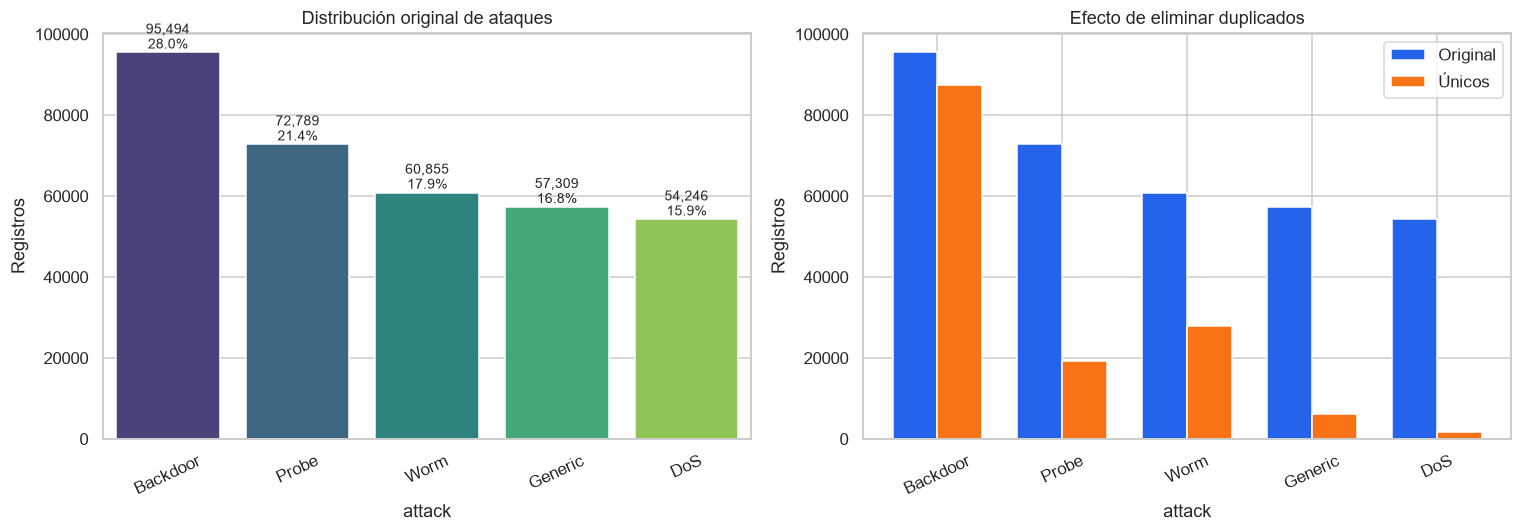

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/no_supervisado/01_eda_distribucion_clases.png')

In [3]:
order = class_counts_raw.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = sns.color_palette("viridis", len(order))
sns.barplot(x=class_counts_raw.index, y=class_counts_raw.values, hue=class_counts_raw.index, ax=axes[0], palette=colors, legend=False)
axes[0].set(title="Distribución original de ataques", xlabel="attack", ylabel="Registros")
axes[0].tick_params(axis="x", rotation=25)
for i, value in enumerate(class_counts_raw.values):
    axes[0].text(i, value, f"{value:,}\n{value/len(df_raw):.1%}", ha="center", va="bottom", fontsize=9)

unique_aligned = class_counts_unique.reindex(order)
x = np.arange(len(order))
axes[1].bar(x - 0.18, class_counts_raw.reindex(order).values, width=0.36, label="Original", color="#2563EB")
axes[1].bar(x + 0.18, unique_aligned.values, width=0.36, label="Únicos", color="#F97316")
axes[1].set_xticks(x, order, rotation=25)
axes[1].set(title="Efecto de eliminar duplicados", xlabel="attack", ylabel="Registros")
axes[1].legend()
savefig("01_eda_distribucion_clases.png")

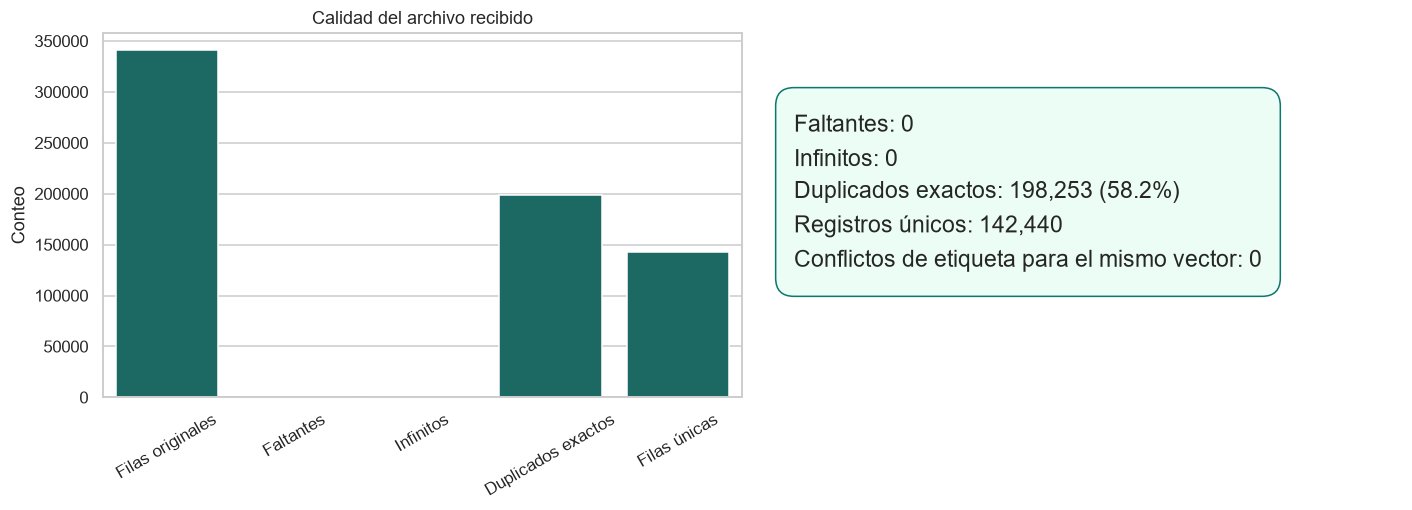

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/no_supervisado/02_eda_calidad_duplicados.png')

In [4]:
quality = pd.DataFrame({
    "indicador": ["Filas originales", "Faltantes", "Infinitos", "Duplicados exactos", "Filas únicas"],
    "valor": [len(df_raw), missing_total, inf_total, exact_duplicates, len(df)]
})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(data=quality, x="indicador", y="valor", ax=axes[0], color="#0F766E")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set(title="Calidad del archivo recibido", xlabel="", ylabel="Conteo")
axes[1].axis("off")
quality_text = (
    f"Faltantes: {missing_total:,}\n"
    f"Infinitos: {inf_total:,}\n"
    f"Duplicados exactos: {exact_duplicates:,} ({exact_duplicates/len(df_raw):.1%})\n"
    f"Registros únicos: {len(df):,}\n"
    f"Conflictos de etiqueta para el mismo vector: {conflicting_feature_groups}"
)
axes[1].text(0.05, 0.8, quality_text, fontsize=15, va="top", linespacing=1.6,
             bbox=dict(boxstyle="round,pad=0.8", facecolor="#ECFDF5", edgecolor="#0F766E"))
savefig("02_eda_calidad_duplicados.png")

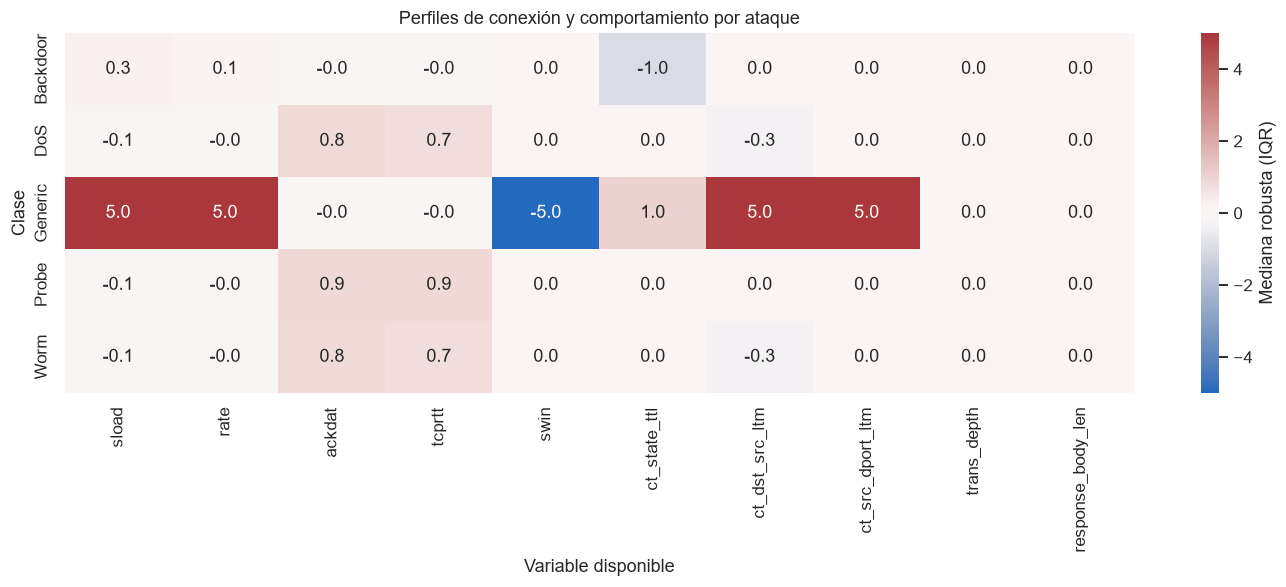

Variables destacadas por grupo: ['sload', 'rate', 'ackdat', 'tcprtt', 'swin', 'ct_state_ttl', 'ct_dst_src_ltm', 'ct_src_dport_ltm', 'trans_depth', 'response_body_len']


In [5]:
feature_groups = {
    "volumen_tasa": ["spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload", "sloss", "dloss", "smean", "dmean"],
    "tiempo": ["dur", "sinpkt", "dinpkt", "sjit", "djit", "tcprtt", "synack", "ackdat"],
    "estado_conexion": ["sttl", "dttl", "swin", "dwin", "ct_state_ttl"],
    "contexto": [c for c in FEATURES if c.startswith("ct_") and c != "ct_state_ttl"],
    "aplicacion": ["trans_depth", "response_body_len", "is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd", "is_sm_ips_ports"]
}
# Perfil robusto: medianas por clase, estandarizadas por mediana/IQR global.
medians = df.groupby(TARGET)[FEATURES].median()
global_med = df[FEATURES].median()
iqr = (df[FEATURES].quantile(.75) - df[FEATURES].quantile(.25)).replace(0, 1)
robust_profile = ((medians - global_med) / iqr).clip(-5, 5)
profile_features = []
for group, cols in feature_groups.items():
    # dos variables con mayor variación entre clases por grupo
    profile_features += robust_profile[cols].var().nlargest(min(2, len(cols))).index.tolist()
profile_features = list(dict.fromkeys(profile_features))

plt.figure(figsize=(13, 5.5))
sns.heatmap(robust_profile[profile_features], cmap="vlag", center=0, annot=True, fmt=".1f", cbar_kws={"label": "Mediana robusta (IQR)"})
plt.title("Perfiles de conexión y comportamiento por ataque")
plt.xlabel("Variable disponible")
plt.ylabel("Clase")
savefig("03_eda_perfiles_comportamiento.png")
print("Variables destacadas por grupo:", profile_features)

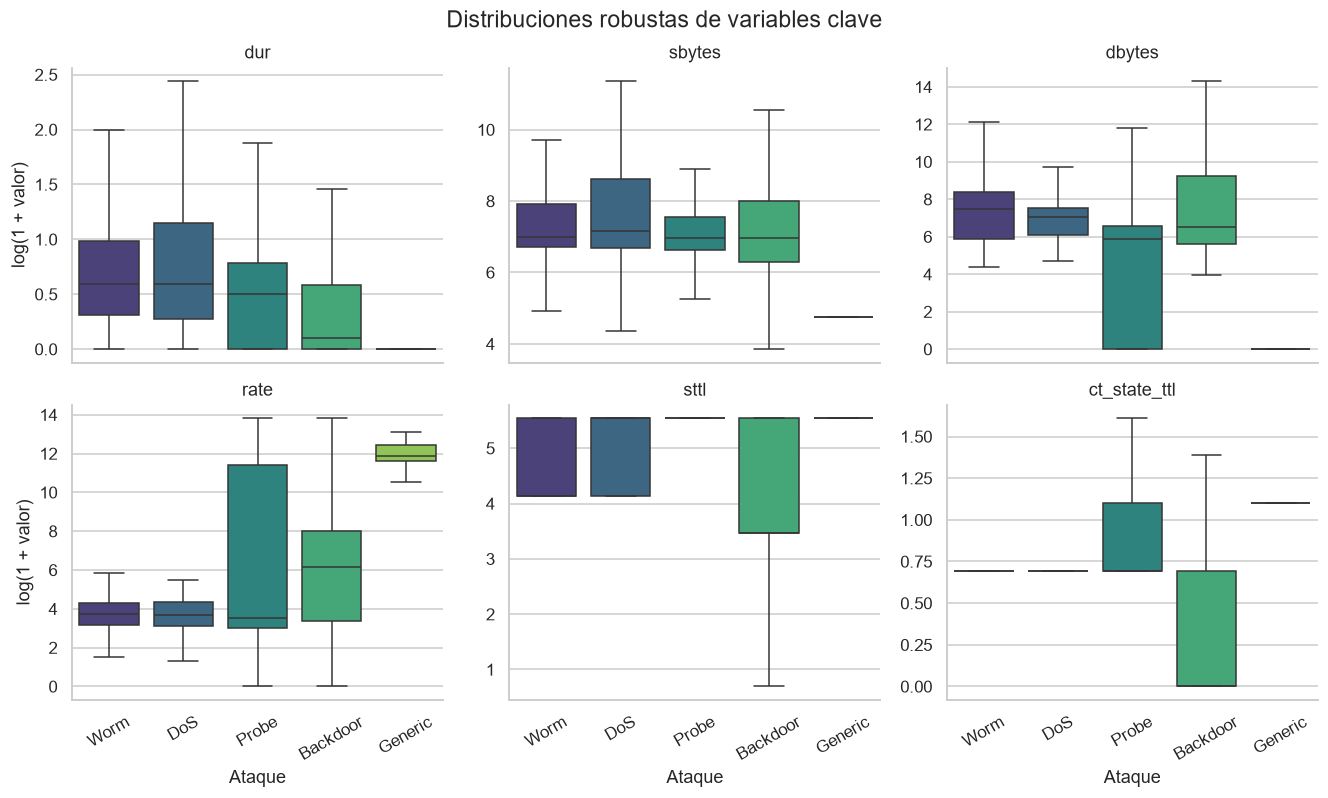

In [6]:
plot_features = ["dur", "sbytes", "dbytes", "rate", "sttl", "ct_state_ttl"]
sample_idx = stratified_sample_indices(df[TARGET], min(30000, len(df)))
eda_sample = df.iloc[sample_idx].copy()
long = eda_sample.melt(id_vars=TARGET, value_vars=plot_features, var_name="variable", value_name="valor")
long["log1p_valor"] = np.log1p(long["valor"].clip(lower=0))
g = sns.catplot(
    data=long, x=TARGET, y="log1p_valor", col="variable", col_wrap=3,
    kind="box", showfliers=False, sharey=False, height=3.4, aspect=1.2,
    hue=TARGET, palette="viridis", legend=False
)
g.set_axis_labels("Ataque", "log(1 + valor)")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=30)
g.fig.suptitle("Distribuciones robustas de variables clave", y=1.02, fontsize=15)
plt.savefig(VIS_DIR / "04_eda_boxplots_log.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

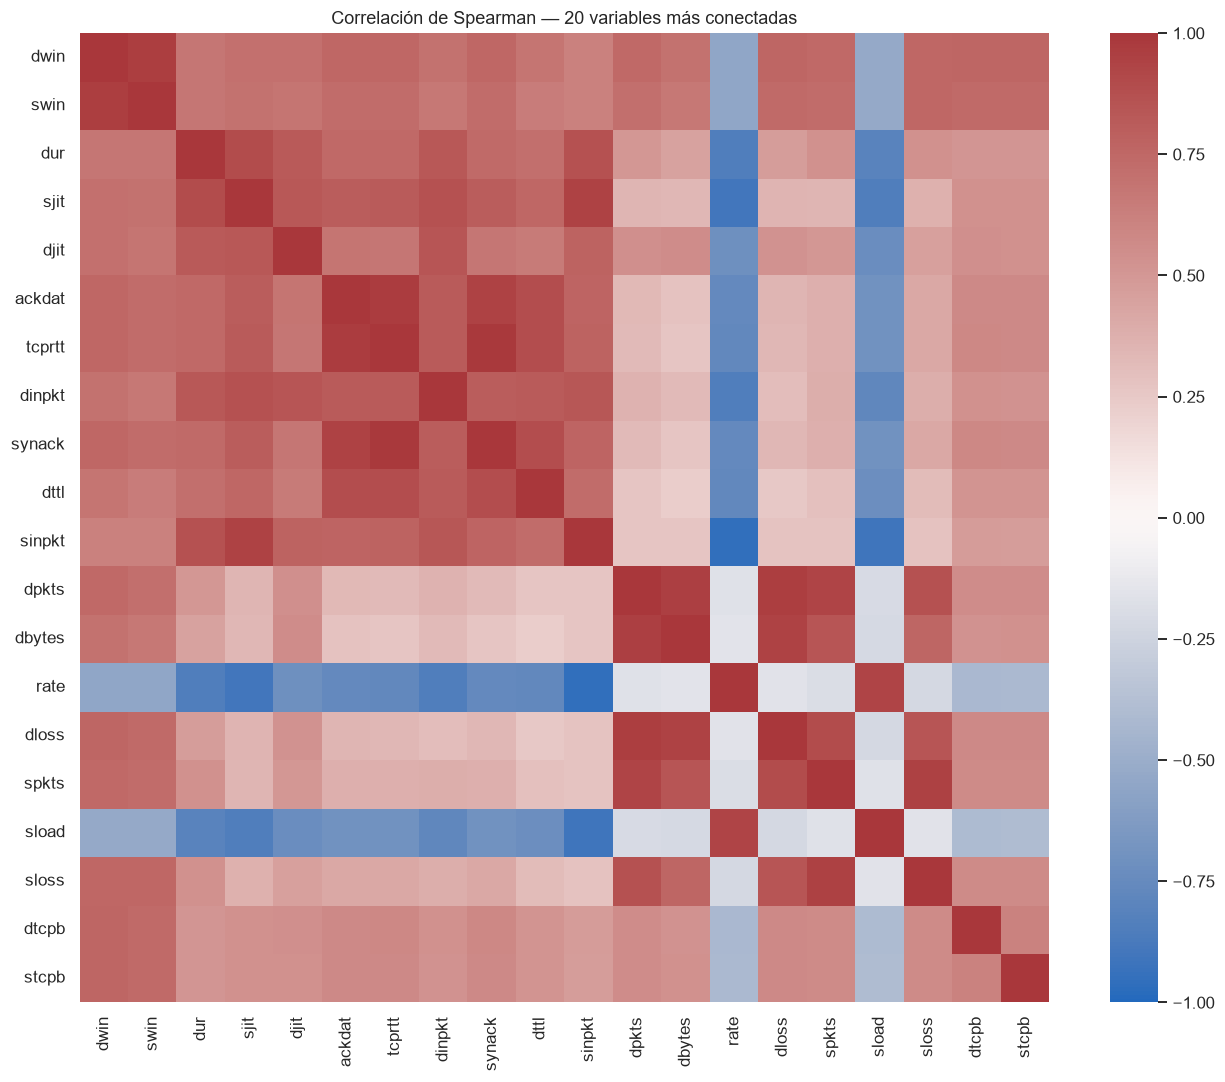

,% outliers IQR
swin,24.13
dmean,20.33
dbytes,20.20
sload,16.96
spkts,15.81
trans_depth,15.41
ct_flw_http_mthd,15.41
rate,14.35
smean,14.22
djit,13.74


In [7]:
corr = df[FEATURES].corr(method="spearman")
# Mostrar las 20 variables con mayor correlación media absoluta para conservar legibilidad.
selected_corr = corr.abs().mean().nlargest(20).index
plt.figure(figsize=(12, 10))
sns.heatmap(corr.loc[selected_corr, selected_corr], cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Spearman — 20 variables más conectadas")
savefig("05_eda_correlacion_spearman.png")

# Porcentaje de outliers por regla IQR en registros únicos.
q1, q3 = df[FEATURES].quantile(.25), df[FEATURES].quantile(.75)
iqr_raw = q3 - q1
outlier_rate = (((df[FEATURES] < (q1 - 1.5 * iqr_raw)) | (df[FEATURES] > (q3 + 1.5 * iqr_raw))).mean() * 100).sort_values(ascending=False)
display(outlier_rate.head(10).rename("% outliers IQR").to_frame().round(2))

## 3. Preprocesamiento y muestreo sin usar la etiqueta como variable de entrada

Se eliminan duplicados exactos antes de modelar para que repeticiones masivas no dominen las
distancias. Por costo computacional se toma una muestra estratificada reproducible de 25.000 registros;
`attack` solo determina las proporciones de muestreo y se separa inmediatamente. El pipeline recibe
exclusivamente las 39 columnas numéricas. Se aplica RobustScaler, que centra con la mediana y escala con el IQR para reducir el efecto de
los valores extremos. Finalmente, PCA conserva al menos 90 % de la varianza antes de K-Means y GMM.

**Algoritmos.** K-Means es rápido e interpretable, pero supone grupos aproximadamente esféricos y usa
distancias euclidianas. GMM permite pertenencia probabilística y componentes con distinta dispersión,
aunque es sensible a inicialización y a la especificación de covarianza.

In [8]:
X_all = df[FEATURES].copy()
y_text_all = df[TARGET].copy()  # solo muestreo e interpretación post-hoc
label_encoder = LabelEncoder().fit(y_text_all)
y_posthoc_all = label_encoder.transform(y_text_all)
class_names = label_encoder.classes_.tolist()

cluster_idx = stratified_sample_indices(y_text_all, min(25000, len(y_text_all)), RANDOM_STATE + 11)
X_cluster_raw = X_all.iloc[cluster_idx].reset_index(drop=True)
attack_cluster = y_text_all.iloc[cluster_idx].reset_index(drop=True)
y_cluster_true = y_posthoc_all[cluster_idx]

# A partir de aquí, estas transformaciones y modelos solo reciben X_cluster_raw.
CLUSTER_FEATURES = list(FEATURES)
# RobustScaler centra con la mediana y escala con el IQR para reducir el efecto de los extremos.
cluster_scaler = RobustScaler().fit(X_cluster_raw[CLUSTER_FEATURES])
X_cluster_scaled = cluster_scaler.transform(X_cluster_raw[CLUSTER_FEATURES])
pca_probe = PCA(random_state=RANDOM_STATE).fit(X_cluster_scaled)
n_pca = max(2, int(np.searchsorted(np.cumsum(pca_probe.explained_variance_ratio_), 0.90) + 1))
pca_cluster = PCA(n_components=n_pca, random_state=RANDOM_STATE).fit(X_cluster_scaled)
X_cluster = pca_cluster.transform(X_cluster_scaled)
print(f"Muestra: {len(X_cluster):,} | variables originales: {len(FEATURES)} | PCA 90%: {X_cluster.shape[1]} componentes")
print("attack no está en X_cluster_raw:", TARGET not in X_cluster_raw.columns)

Muestra: 25,000 | variables originales: 39 | PCA 90%: 2 componentes
attack no está en X_cluster_raw: True


## 4. Componente no supervisado: K-Means y GMM

Se toma una muestra estratificada de 25.000 registros **solo para conservar representación**; la
etiqueta no entra a escalamiento, PCA, K-Means ni GMM. Ambos algoritmos reciben la misma matriz PCA.
PCA conserva al menos 90% de la varianza para estabilizar distancias y covarianzas. K-Means elige `k`
mediante un ranking conjunto de Silhouette, Davies–Bouldin y Calinski–Harabasz; GMM minimiza BIC.

In [9]:
k_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=15, max_iter=400, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_cluster)
    k_rows.append({
        "k": k,
        "silhouette": silhouette_score(X_cluster, labels, sample_size=min(5000, len(labels)), random_state=RANDOM_STATE),
        "davies_bouldin": davies_bouldin_score(X_cluster, labels),
        "calinski_harabasz": calinski_harabasz_score(X_cluster, labels),
        "inercia": km.inertia_
    })
k_df = pd.DataFrame(k_rows)
k_df["rank_compuesto"] = (
    k_df["silhouette"].rank(ascending=False) +
    k_df["davies_bouldin"].rank(ascending=True) +
    k_df["calinski_harabasz"].rank(ascending=False)
)
best_k = int(k_df.sort_values(["rank_compuesto", "k"]).iloc[0]["k"])
kmeans = KMeans(n_clusters=best_k, n_init=30, max_iter=500, random_state=RANDOM_STATE).fit(X_cluster)
kmeans_labels = kmeans.labels_
k_df.to_csv(RES_DIR / "seleccion_kmeans.csv", index=False)
print(f"K-Means seleccionado sin etiquetas: k={best_k}")
display(k_df.style.format({"silhouette":"{:.4f}", "davies_bouldin":"{:.4f}", "calinski_harabasz":"{:.1f}", "inercia":"{:.1f}"}))

K-Means seleccionado sin etiquetas: k=5


,k,silhouette,davies_bouldin,calinski_harabasz,inercia,rank_compuesto
0,2,0.9992,0.1039,64231.4,37643051396841.0,11.000000
1,3,0.9980,0.1321,265508.7,6040732427412.2,13.500000
2,4,0.9980,0.1399,325137.9,3357224606253.9,13.500000
3,5,0.9977,0.0422,374685.2,2204099786584.7,9.500000
4,6,0.9977,0.0559,522768.1,1272657143173.1,9.500000
5,7,0.9954,0.1315,1355207.7,411733511259.5,12.000000
6,8,0.9900,0.2125,1814296.5,263893490008.4,15.000000


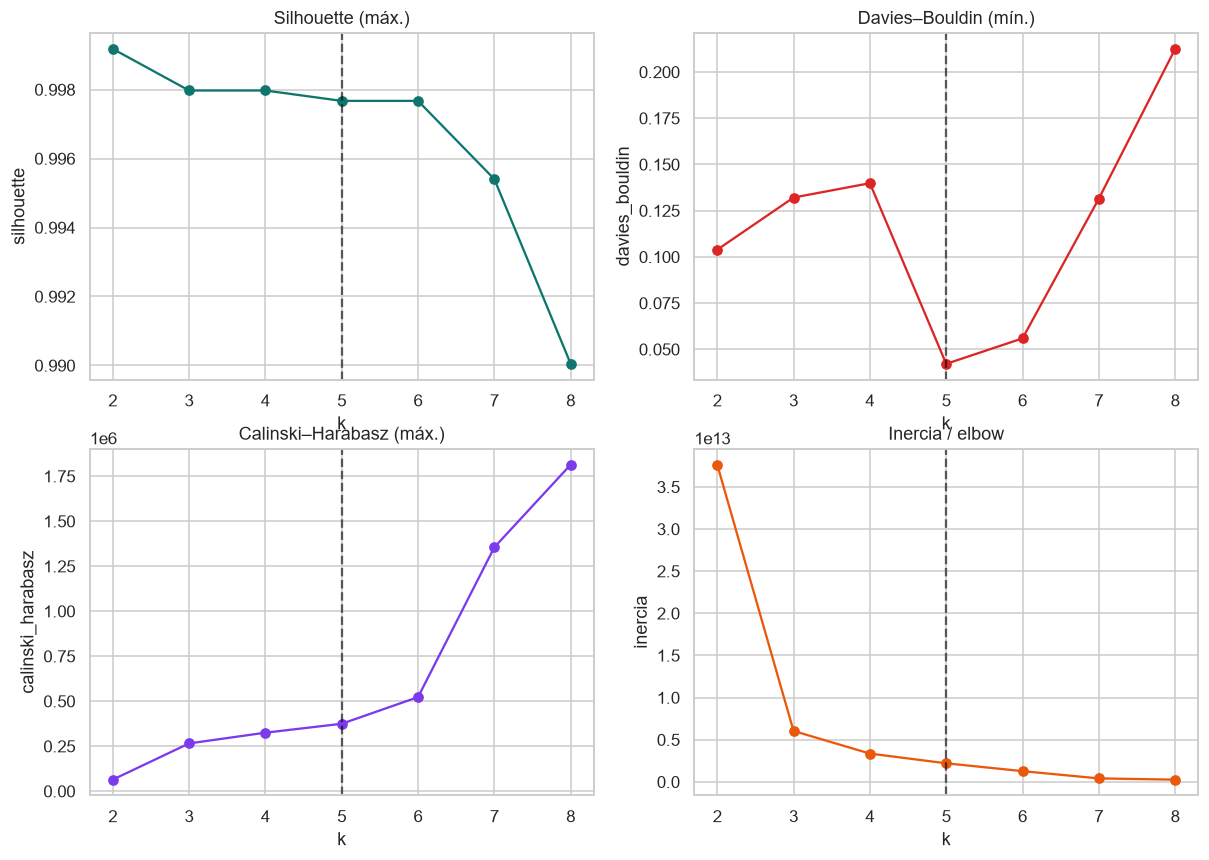

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plots = [
    ("silhouette", "Silhouette (máx.)", "#0F766E"),
    ("davies_bouldin", "Davies–Bouldin (mín.)", "#DC2626"),
    ("calinski_harabasz", "Calinski–Harabasz (máx.)", "#7C3AED"),
    ("inercia", "Inercia / elbow", "#EA580C")
]
for ax, (col, title, color) in zip(axes.flat, plots):
    ax.plot(k_df["k"], k_df[col], marker="o", color=color)
    ax.axvline(best_k, ls="--", color="black", alpha=.6)
    ax.set(title=title, xlabel="k", ylabel=col)
plt.savefig(VIS_DIR / "14_kmeans_seleccion_k.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

In [11]:
gmm_search = []
for covariance_type in ["diag", "tied"]:
    for n_components in range(2, 9):
        try:
            gm = GaussianMixture(
                n_components=n_components, covariance_type=covariance_type,
                reg_covar=1e-3, n_init=2, max_iter=250, random_state=RANDOM_STATE
            ).fit(X_cluster)
            gmm_search.append({
                "n_components": n_components, "covariance_type": covariance_type,
                "BIC": gm.bic(X_cluster), "AIC": gm.aic(X_cluster)
            })
        except ValueError as exc:
            print(f"GMM omitido: k={n_components}, cov={covariance_type}: {str(exc).splitlines()[0]}")
gmm_df = pd.DataFrame(gmm_search)
best_gmm_row = gmm_df.loc[gmm_df["BIC"].idxmin()]
best_n = int(best_gmm_row["n_components"])
best_cov = str(best_gmm_row["covariance_type"])
gmm = GaussianMixture(
    n_components=best_n, covariance_type=best_cov, reg_covar=1e-3,
    n_init=5, max_iter=400, random_state=RANDOM_STATE
).fit(X_cluster)
gmm_labels = gmm.predict(X_cluster)
gmm_df.to_csv(RES_DIR / "seleccion_gmm.csv", index=False)
print(f"GMM seleccionado por BIC: componentes={best_n}, covarianza={best_cov}")
display(gmm_df.sort_values("BIC").head(10).style.format({"BIC":"{:.0f}", "AIC":"{:.0f}"}))

GMM seleccionado por BIC: componentes=8, covarianza=diag


,n_components,covariance_type,BIC,AIC
6,8,diag,279715,279398
5,7,diag,282260,281983
4,6,diag,286288,286053
2,4,diag,293464,293309
1,3,diag,293466,293352
3,5,diag,311913,311718
0,2,diag,327061,326988
13,8,tied,830032,829821
12,7,tied,840526,840339
11,6,tied,868282,868119


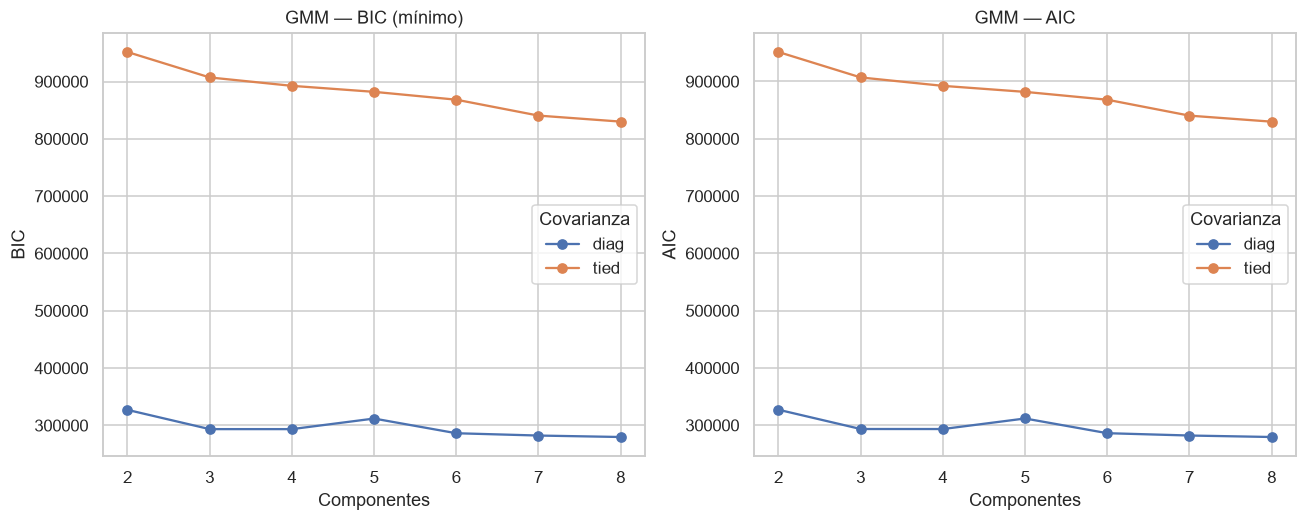

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for cov, part in gmm_df.groupby("covariance_type"):
    axes[0].plot(part["n_components"], part["BIC"], marker="o", label=cov)
    axes[1].plot(part["n_components"], part["AIC"], marker="o", label=cov)
axes[0].set(title="GMM — BIC (mínimo)", xlabel="Componentes", ylabel="BIC")
axes[1].set(title="GMM — AIC", xlabel="Componentes", ylabel="AIC")
for ax in axes: ax.legend(title="Covarianza")
plt.savefig(VIS_DIR / "15_gmm_bic_aic.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

In [13]:
def cluster_metrics(name, labels):
    return {
        "Modelo": name,
        "Clusters": len(np.unique(labels)),
        "Silhouette": silhouette_score(X_cluster, labels, sample_size=min(5000, len(labels)), random_state=RANDOM_STATE),
        "Davies-Bouldin": davies_bouldin_score(X_cluster, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_cluster, labels),
        "ARI (post-hoc)": adjusted_rand_score(y_cluster_true, labels),
        "NMI (post-hoc)": normalized_mutual_info_score(y_cluster_true, labels),
        "Homogeneidad": homogeneity_score(y_cluster_true, labels),
        "Completitud": completeness_score(y_cluster_true, labels),
        "V-measure": v_measure_score(y_cluster_true, labels),
        "Pureza": purity_score(y_cluster_true, labels),
    }

clustering_metrics = pd.DataFrame([
    cluster_metrics(f"K-Means (k={best_k})", kmeans_labels),
    cluster_metrics(f"GMM (k={best_n}, {best_cov})", gmm_labels)
]).set_index("Modelo")
clustering_metrics.to_csv(RES_DIR / "metricas_clustering.csv")
display(clustering_metrics.style.format("{:.4f}"))

,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (post-hoc),NMI (post-hoc),Homogeneidad,Completitud,V-measure,Pureza
Modelo,,,,,,,,,,
K-Means (k=5),5.0000,0.9977,0.0422,374685.1888,-0.0025,0.0042,0.0021,0.0809,0.0042,0.6146
"GMM (k=8, diag)",8.0000,0.8037,0.8410,100198.7632,0.0231,0.0568,0.0396,0.1004,0.0568,0.6184


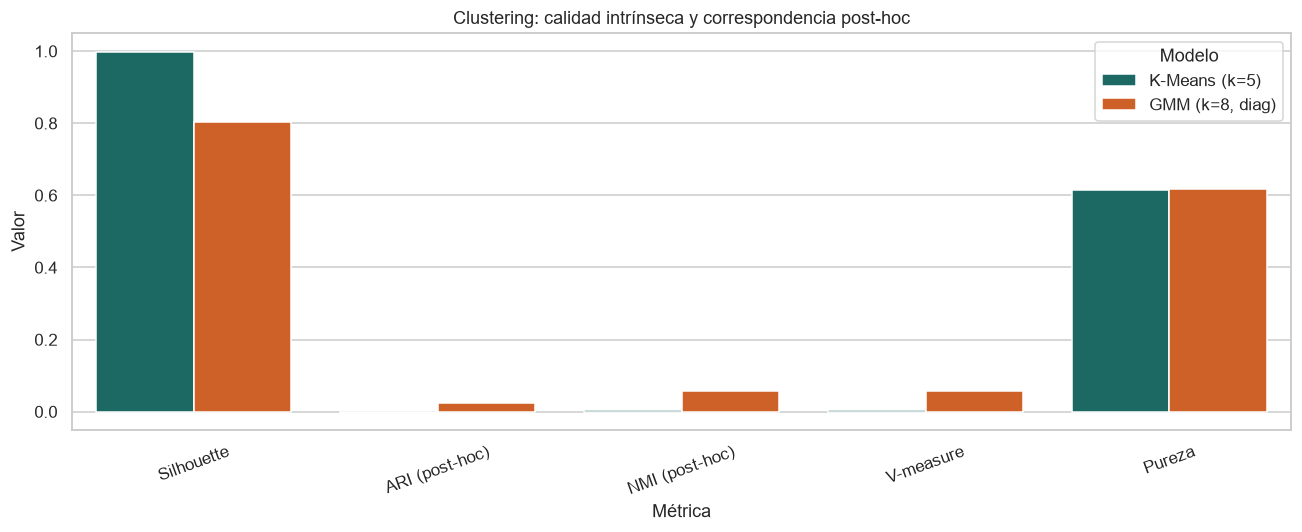

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/no_supervisado/16_clustering_comparacion_metricas.png')

In [14]:
metric_plot = clustering_metrics[["Silhouette", "ARI (post-hoc)", "NMI (post-hoc)", "V-measure", "Pureza"]].reset_index().melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
plt.figure(figsize=(12, 5))
sns.barplot(data=metric_plot, x="Métrica", y="Valor", hue="Modelo", palette=["#0F766E", "#EA580C"])
plt.title("Clustering: calidad intrínseca y correspondencia post-hoc")
plt.ylim(-0.05, 1.05)
plt.xticks(rotation=20)
savefig("16_clustering_comparacion_metricas.png")

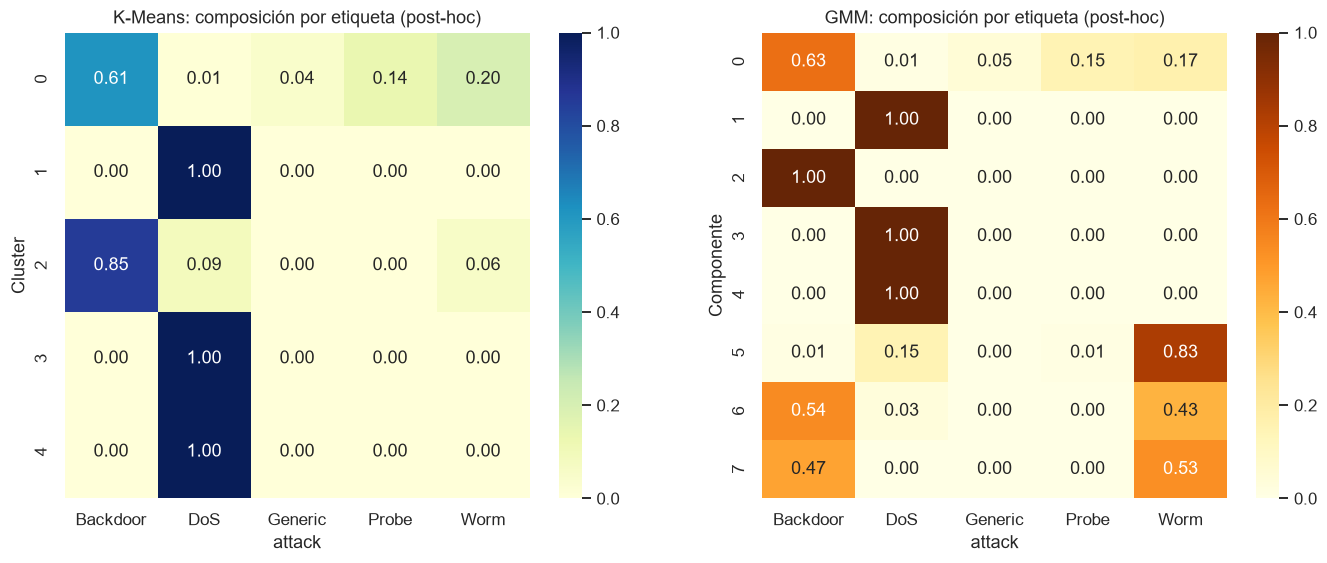

In [15]:
k_cross = pd.crosstab(pd.Series(kmeans_labels, name="Cluster"), attack_cluster, normalize="index")
g_cross = pd.crosstab(pd.Series(gmm_labels, name="Componente"), attack_cluster, normalize="index")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(k_cross, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0])
sns.heatmap(g_cross, annot=True, fmt=".2f", cmap="YlOrBr", ax=axes[1])
axes[0].set_title("K-Means: composición por etiqueta (post-hoc)")
axes[1].set_title("GMM: composición por etiqueta (post-hoc)")
plt.savefig(VIS_DIR / "17_clustering_correspondencia_etiquetas.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()
k_cross.to_csv(RES_DIR / "crosstab_kmeans.csv")
g_cross.to_csv(RES_DIR / "crosstab_gmm.csv")

## 5. Perfiles de clusters y análisis de anomalías

Los perfiles se calculan en la escala original mediante medianas robustas. Para anomalías se combinan
dos perspectivas: distancia al centroide K-Means y log-verosimilitud negativa de GMM. Se reporta el 1%
superior de cada score. `attack` solo se consulta después para describir qué etiquetas quedaron allí.

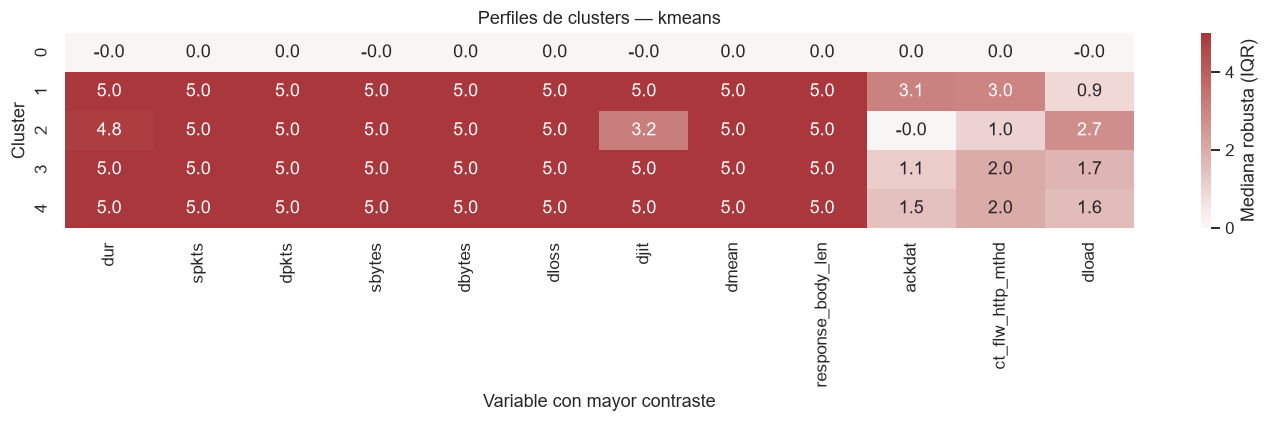

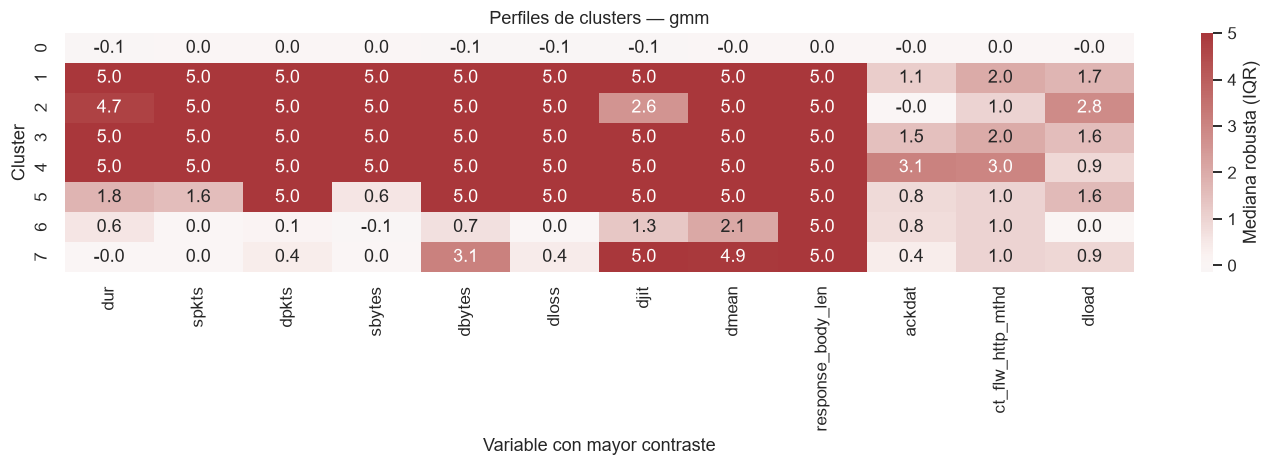

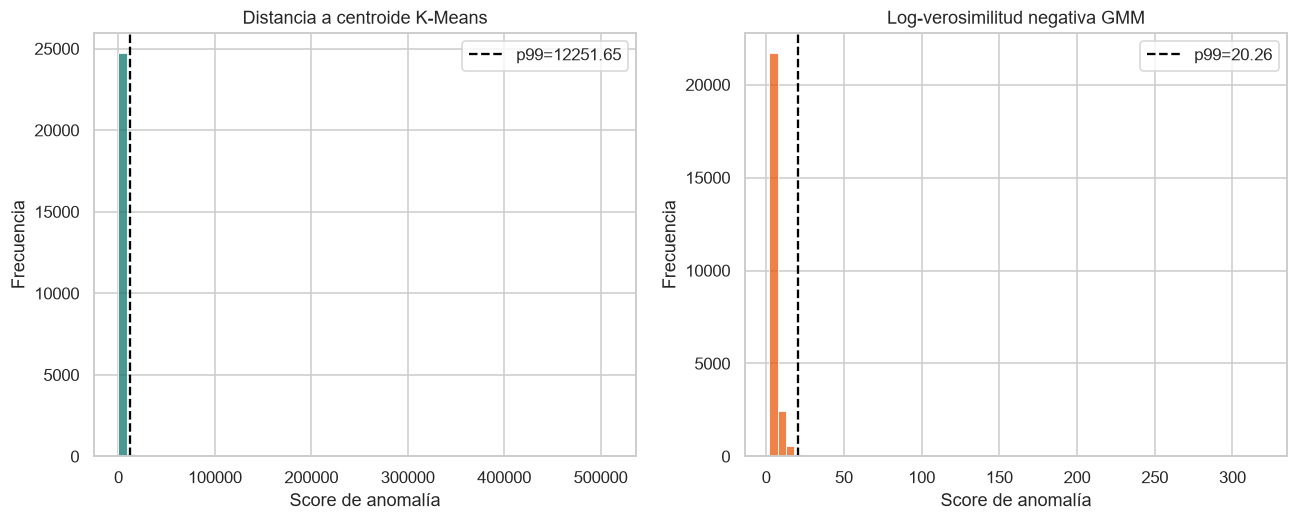

,KMeans_top1pct,GMM_top1pct,Muestra_total
attack_posthoc,,,
Backdoor,35.20%,8.40%,61.44%
DoS,3.20%,6.00%,1.20%
Generic,0.00%,0.00%,4.29%
Probe,0.00%,53.60%,13.48%
Worm,61.60%,32.00%,19.58%


In [16]:
def robust_cluster_profile(labels, name):
    prof = X_cluster_raw.assign(cluster=labels).groupby("cluster")[FEATURES].median()
    global_med = X_cluster_raw[FEATURES].median()
    global_iqr = (X_cluster_raw[FEATURES].quantile(.75) - X_cluster_raw[FEATURES].quantile(.25)).replace(0, 1)
    z = ((prof - global_med) / global_iqr).clip(-5, 5)
    top = z.abs().max().nlargest(12).index
    z[top].to_csv(RES_DIR / f"perfiles_{name}.csv")
    plt.figure(figsize=(13, max(4, .55 * len(z))))
    sns.heatmap(z[top], cmap="vlag", center=0, annot=True, fmt=".1f", cbar_kws={"label": "Mediana robusta (IQR)"})
    plt.title(f"Perfiles de clusters — {name}")
    plt.xlabel("Variable con mayor contraste")
    plt.ylabel("Cluster")
    savefig(f"18_perfiles_{name}.png")
    return z

k_profiles = robust_cluster_profile(kmeans_labels, "kmeans")
g_profiles = robust_cluster_profile(gmm_labels, "gmm")

# Scores altos = más anómalo.
k_dist = np.linalg.norm(X_cluster - kmeans.cluster_centers_[kmeans_labels], axis=1)
g_nll = -gmm.score_samples(X_cluster)
k_cut = float(np.quantile(k_dist, .99))
g_cut = float(np.quantile(g_nll, .99))
anomaly_df = pd.DataFrame({
    "attack_posthoc": attack_cluster,
    "kmeans_distance": k_dist,
    "gmm_neg_loglik": g_nll,
    "anomalia_kmeans_1pct": k_dist >= k_cut,
    "anomalia_gmm_1pct": g_nll >= g_cut,
})
anomaly_summary = pd.DataFrame({
    "KMeans_top1pct": anomaly_df.loc[anomaly_df["anomalia_kmeans_1pct"], "attack_posthoc"].value_counts(normalize=True),
    "GMM_top1pct": anomaly_df.loc[anomaly_df["anomalia_gmm_1pct"], "attack_posthoc"].value_counts(normalize=True),
    "Muestra_total": anomaly_df["attack_posthoc"].value_counts(normalize=True),
}).fillna(0)
anomaly_summary.to_csv(RES_DIR / "anomalias_composicion_posthoc.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(k_dist, bins=60, ax=axes[0], color="#0F766E")
axes[0].axvline(k_cut, ls="--", color="black", label=f"p99={k_cut:.2f}")
axes[0].set(title="Distancia a centroide K-Means", xlabel="Score de anomalía", ylabel="Frecuencia")
axes[0].legend()
sns.histplot(g_nll, bins=60, ax=axes[1], color="#EA580C")
axes[1].axvline(g_cut, ls="--", color="black", label=f"p99={g_cut:.2f}")
axes[1].set(title="Log-verosimilitud negativa GMM", xlabel="Score de anomalía", ylabel="Frecuencia")
axes[1].legend()
plt.savefig(VIS_DIR / "19_scores_anomalia.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()
display(anomaly_summary.style.format("{:.2%}"))

## 6. Reducción de dimensionalidad: PCA, biplot y t-SNE

PCA es lineal y cuantifica varianza global; t-SNE preserva vecindades locales y no permite interpretar
distancias globales ni varianza explicada. Las etiquetas se usan únicamente para colorear después de
calcular las proyecciones.

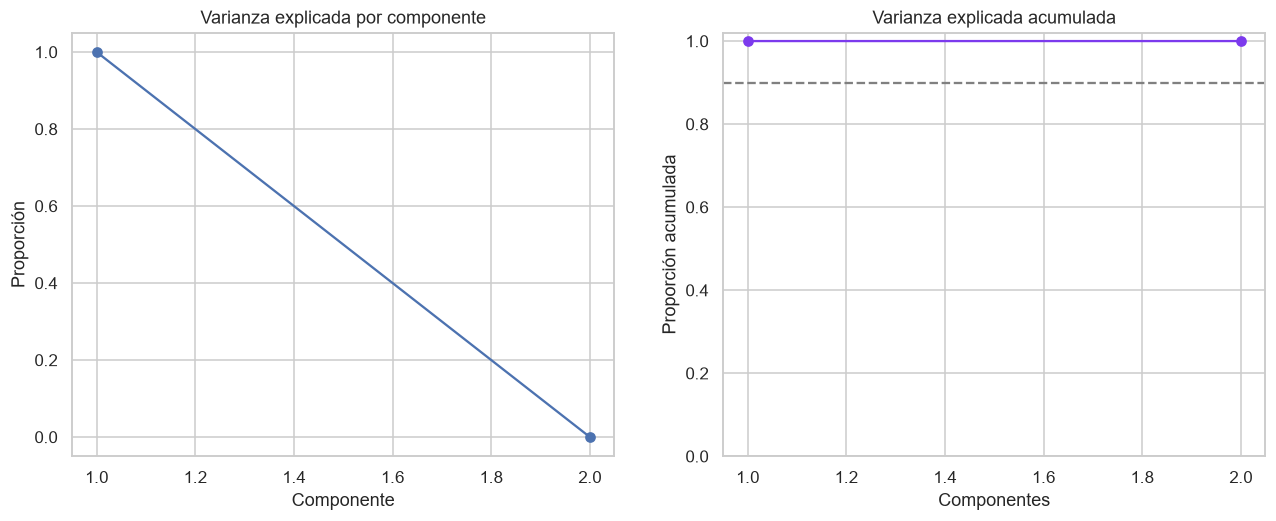

PC1+PC2 explican 100.00%; 2 componentes conservan 100.00%.


In [17]:
explained = pca_cluster.explained_variance_ratio_
cumulative = np.cumsum(explained)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.arange(1, len(explained)+1), explained, marker="o")
axes[0].set(title="Varianza explicada por componente", xlabel="Componente", ylabel="Proporción")
axes[1].plot(np.arange(1, len(cumulative)+1), cumulative, marker="o", color="#7C3AED")
axes[1].axhline(.90, ls="--", color="gray")
axes[1].set(title="Varianza explicada acumulada", xlabel="Componentes", ylabel="Proporción acumulada", ylim=(0, 1.02))
plt.savefig(VIS_DIR / "20_pca_varianza.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()
print(f"PC1+PC2 explican {cumulative[1]:.2%}; {len(explained)} componentes conservan {cumulative[-1]:.2%}.")

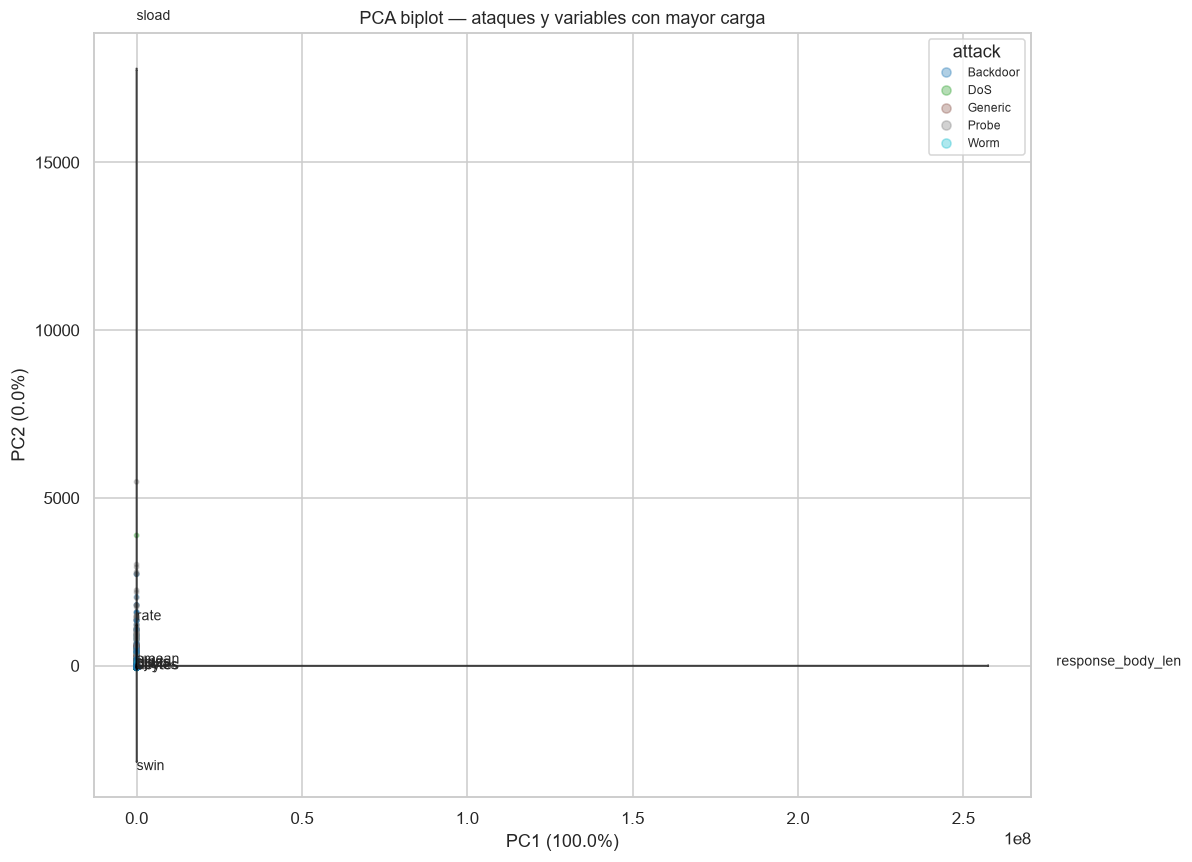

WindowsPath('g:/Mi unidad/ITM/2026-2/Analisis de datos/Entregable 4/entregable-machine-learning-2026-2/visualizaciones/no_supervisado/21_pca_biplot.png')

In [18]:
# Biplot sobre una submuestra para legibilidad.
vis_idx = stratified_sample_indices(y_cluster_true, min(5000, len(y_cluster_true)), RANDOM_STATE + 22)
coords = X_cluster[vis_idx, :2]
loadings = pca_cluster.components_[:2].T * np.sqrt(pca_cluster.explained_variance_[:2])
top_loading_idx = np.linalg.norm(loadings, axis=1).argsort()[-10:]

plt.figure(figsize=(11, 8))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=y_cluster_true[vis_idx], s=8, alpha=.35, cmap="tab10")
scale_x = np.percentile(np.abs(coords[:, 0]), 85)
scale_y = np.percentile(np.abs(coords[:, 1]), 85)
for i in top_loading_idx:
    x, yv = loadings[i, 0] * scale_x, loadings[i, 1] * scale_y
    plt.arrow(0, 0, x, yv, color="black", alpha=.7, head_width=max(scale_x, scale_y)*.015, length_includes_head=True)
    plt.text(x*1.08, yv*1.08, CLUSTER_FEATURES[i], fontsize=9)
plt.title("PCA biplot — ataques y variables con mayor carga")
plt.xlabel(f"PC1 ({explained[0]:.1%})")
plt.ylabel(f"PC2 ({explained[1]:.1%})")
handles, _ = scatter.legend_elements()
plt.legend(handles, class_names, title="attack", loc="best", fontsize=8)
savefig("21_pca_biplot.png")

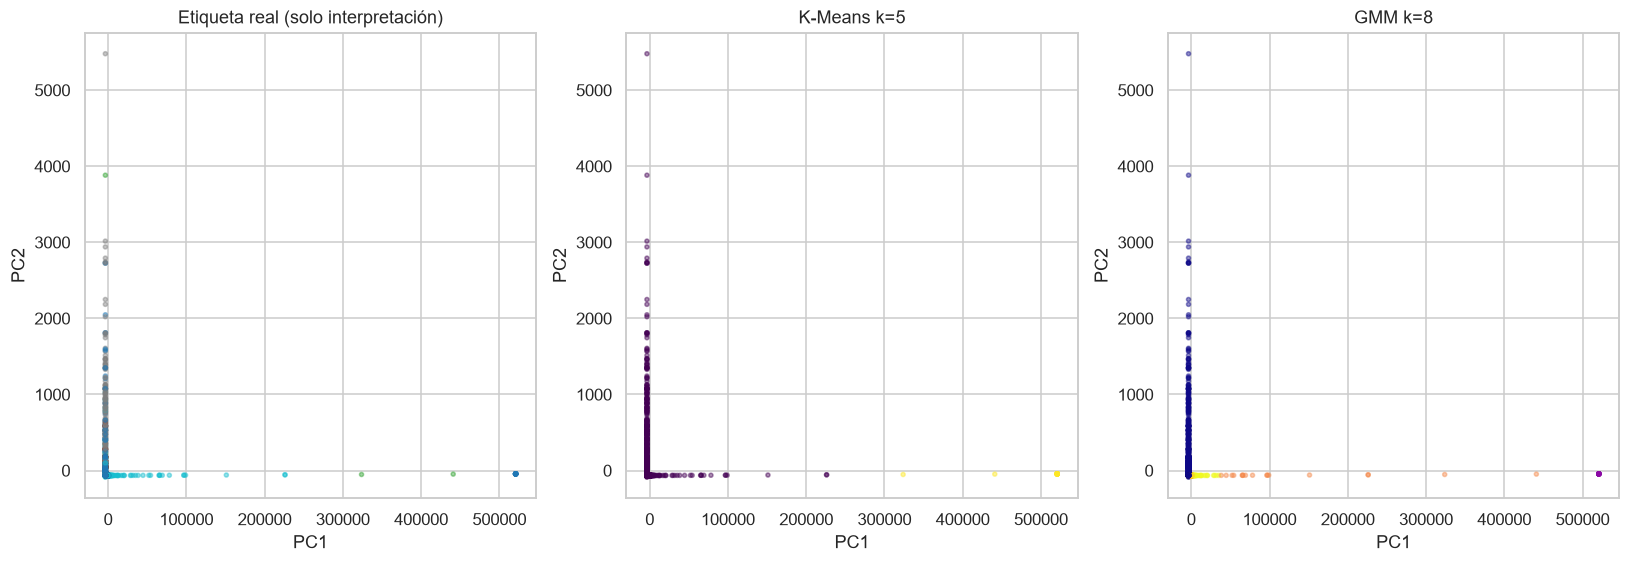

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colorings = [
    (y_cluster_true[vis_idx], "Etiqueta real (solo interpretación)", "tab10"),
    (kmeans_labels[vis_idx], f"K-Means k={best_k}", "viridis"),
    (gmm_labels[vis_idx], f"GMM k={best_n}", "plasma")
]
for ax, (colors_, title, cmap) in zip(axes, colorings):
    ax.scatter(coords[:, 0], coords[:, 1], c=colors_, s=7, alpha=.45, cmap=cmap)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
plt.savefig(VIS_DIR / "22_pca_comparacion.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

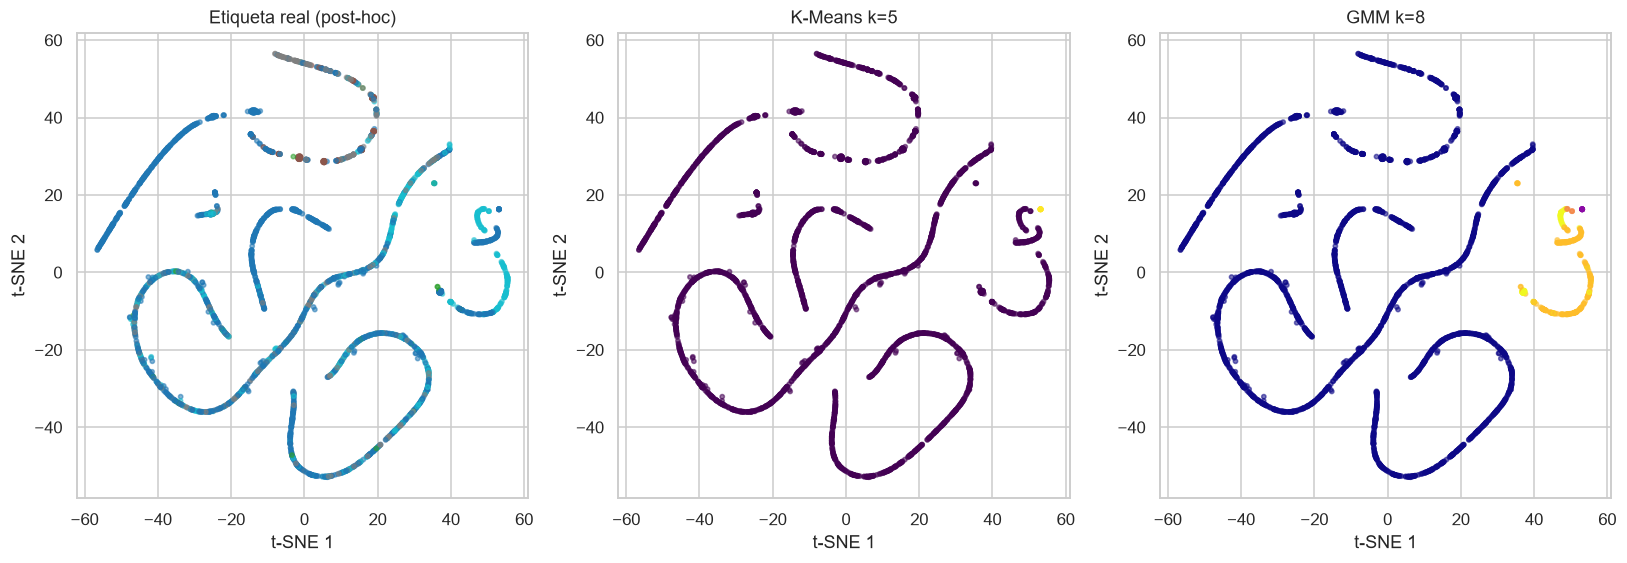

In [20]:
tsne_idx = stratified_sample_indices(y_cluster_true, min(3000, len(y_cluster_true)), RANDOM_STATE + 33)
tsne_kwargs = dict(n_components=2, perplexity=30, learning_rate="auto", init="pca", random_state=RANDOM_STATE)
# Compatibilidad entre versiones de scikit-learn.
try:
    tsne = TSNE(max_iter=750, **tsne_kwargs)
except TypeError:
    tsne = TSNE(n_iter=750, **tsne_kwargs)
X_tsne = tsne.fit_transform(X_cluster[tsne_idx])
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
tsne_colorings = [
    (y_cluster_true[tsne_idx], "Etiqueta real (post-hoc)", "tab10"),
    (kmeans_labels[tsne_idx], f"K-Means k={best_k}", "viridis"),
    (gmm_labels[tsne_idx], f"GMM k={best_n}", "plasma")
]
for ax, (colors_, title, cmap) in zip(axes, tsne_colorings):
    ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=colors_, s=8, alpha=.55, cmap=cmap)
    ax.set(title=title, xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.savefig(VIS_DIR / "23_tsne_comparacion.png", bbox_inches="tight", dpi=180)
plt.show(); plt.close()

## 7. Reflexión comparativa supervisado vs no supervisado (sección 5)

1. **Problema de cada componente.** El supervisado asigna una de cinco etiquetas conocidas; el no
   supervisado resume estructura, perfiles y extremos sin utilizar `attack` como predictor.
2. **Algoritmos y pertinencia.** LR es un baseline lineal interpretable; SVM RBF captura fronteras no
   lineales; One-Class SVM estudia novedad. K-Means ofrece una partición simple y GMM pertenencia
   probabilística. Todos requieren escalamiento por las magnitudes heterogéneas.
3. **Dificultades.** Hay duplicados masivos, fuerte cambio de prevalencias al deduplicar, colas extremas
   y SVM costoso. Se aplican deduplicación, RobustScaler y muestras reproducibles; los efectos del
   muestreo se declaran.
4. **Casos de interés supervisados.** Se juzgan con F1 macro, recall por clase, matrices y ROC/PR-AUC
   sobre una prueba común; no se equipara accuracy con buen desempeño en clases minoritarias.
5. **Patrones no evidentes.** Las métricas intrínsecas pueden indicar grupos muy compactos, mientras que
   ARI/NMI post-hoc bajos demuestran que esa geometría no reproduce automáticamente la taxonomía.
6. **Relación etiquetas–grupos.** Las tablas de composición muestran mezclas y subdivisiones. La pureza
   debe compararse con la prevalencia de la clase mayoritaria y no convierte clusters en ataques.
7. **Reducción de dimensionalidad.** PCA conserva la fracción reportada de varianza lineal global, pero
   puede concentrarse en variables de gran dispersión; t-SNE conserva vecindades locales y pierde
   distancias globales, varianza explicada y reproducibilidad fuera de la muestra.
8. **Recomendación real.** Para clasificar estos cinco ataques se prefiere el supervisado con mejor F1
   macro. Clustering y scores de anomalía sirven como monitoreo exploratorio/triage, no como detector
   autónomo. Para despliegue normal–malicioso faltan registros Normal, validación temporal y costos.

## 8. Conclusiones y limitaciones

- `k` y el número de componentes se seleccionan sin mirar las etiquetas: ranking intrínseco para
  K-Means y BIC para GMM; AIC se reporta como contraste.
- Silhouette alto no implica correspondencia semántica. ARI, NMI, V-measure, pureza y tablas post-hoc
  deben interpretarse conjuntamente.
- Los clusters describen perfiles matemáticos de las variables disponibles; no hay protocolos,
  servicios, estados ni tráfico Normal para darles significado operativo completo.
- El top 1% de anomalías es un criterio de priorización, no una etiqueta de verdad.
- El muestreo estratificado acelera el análisis, pero puede omitir microestructuras; repetir con otras
  semillas y validar en periodos futuros sería trabajo posterior.

In [21]:
best_cluster_name = clustering_metrics["Silhouette"].idxmax()
summary_unsupervised = {
    "dataset": {"filas_originales": int(len(df_raw)), "filas_unicas": int(len(df)),
                "features": int(len(FEATURES)), "duplicados_exactos": exact_duplicates,
                "sin_proto_service_state": True, "sin_clase_normal": True},
    "muestra_clustering": int(len(X_cluster)),
    "pca_components_90": int(len(explained)),
    "pca_pc1_pc2_variance": float(cumulative[1]),
    "best_kmeans_k": int(best_k),
    "best_gmm_components": int(best_n),
    "best_gmm_covariance": best_cov,
    "clustering": clustering_metrics.reset_index().to_dict(orient="records"),
    "anomaly_thresholds": {"kmeans_p99": k_cut, "gmm_p99": g_cut},
    "mejor_silhouette": best_cluster_name,
    "runtime_minutes": float((time.time() - t0) / 60),
}
with open(RES_DIR / "resumen_no_supervisado.json", "w", encoding="utf-8") as f:
    json.dump(summary_unsupervised, f, ensure_ascii=False, indent=2)
print("Mejor Silhouette:", best_cluster_name)
print(f"Tiempo no supervisado: {summary_unsupervised['runtime_minutes']:.1f} min")
print(f"Visualizaciones: {len(list(VIS_DIR.glob('*.png')))}")
print("La etiqueta se usó solo para muestreo representativo e interpretación post-hoc.")

Mejor Silhouette: K-Means (k=5)
Tiempo no supervisado: 1.1 min
Visualizaciones: 16
La etiqueta se usó solo para muestreo representativo e interpretación post-hoc.
